# 01 · Chuẩn bị dữ liệu và kiểm tra shortcut

Notebook này thay cho các lệnh `fetch_genimage.py` / `src.data.ingest` / `src.data.shortcut_audit` trong README:

1. tải một tập con có seed của GenImage (khoảng 5 GB, tải tiếp được nếu bị ngắt);
2. chuẩn hoá ảnh (JPEG harmonisation + resize-crop 224), chia split theo nhóm ảnh gốc, sinh các biến thể suy giảm;
3. thống kê bộ dữ liệu và kiểm tra **shortcut** (định dạng/kích thước file làm lộ nhãn).

Các bước nặng được tắt mặc định (`RUN_* = False`). Nếu chưa có dữ liệu thật, phần thống kê chạy trên bộ dữ liệu demo.

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, Image, display

from src.core.config import load_config
from src.core.contracts import SplitManifest

pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 40)
cfg = load_config()
print("repo:", ROOT)

repo: c:\Users\Admin\OneDrive - Saigon University\Documents\aegis-ai-forensics


In [ ]:
RUN_DOWNLOAD = True   # ~5 GB, cần mạng
RUN_INGEST = True      # chuẩn hoá + chia split + audit (vài chục phút)
PER_CLASS = 2000
NORMALIZED = "data/normalized_v2"

## 1. Tải dữ liệu GenImage (tập con)

In [3]:
import subprocess
if RUN_DOWNLOAD:
    subprocess.run([sys.executable, "scripts/fetch_genimage.py", "--out", "data/raw/genimage",
                    "--per-class", str(PER_CLASS)], check=True)
else:
    print("bỏ qua bước tải (RUN_DOWNLOAD=False)")

## 2. Chuẩn hoá, chia split, sinh biến thể suy giảm

In [4]:
if RUN_INGEST:
    from src.data.ingest import main as ingest_main
    ingest_main(["--mode", "resize_crop", "--out", NORMALIZED])
else:
    print("bỏ qua ingest (RUN_INGEST=False)")

2026-11-22 05:56:54,564 | INFO    | aegis.src.data.ingest | scanned adm: 2000 ai, 2000 nature
2026-11-22 05:56:56,634 | INFO    | aegis.src.data.ingest | scanned midjourney: 2000 ai, 2000 nature
2026-11-22 05:56:58,137 | INFO    | aegis.src.data.ingest | scanned sd_v1_4: 2000 ai, 2000 nature
2026-11-22 05:56:59,259 | INFO    | aegis.src.data.ingest | scanned vqdm: 2000 ai, 2000 nature
2026-11-22 05:58:01,738 | WARNING | aegis.src.data.pipeline | skip data\raw\genimage\adm\nature\ILSVRC2012_val_00002840.JPEG: too_small: 200x200 < 224
2026-11-22 05:58:01,908 | WARNING | aegis.src.data.pipeline | skip data\raw\genimage\adm\nature\ILSVRC2012_val_00002987.JPEG: too_small: 216x144 < 224
2026-11-22 05:58:02,142 | WARNING | aegis.src.data.pipeline | skip data\raw\genimage\adm\nature\ILSVRC2012_val_00003363.JPEG: too_small: 252x182 < 224
2026-11-22 05:58:04,399 | WARNING | aegis.src.data.pipeline | skip data\raw\genimage\adm\nature\ILSVRC2012_val_00004870.JPEG: too_small: 199x211 < 224
2026-11-

## 3. Thống kê bộ dữ liệu

In [5]:
# Bộ dữ liệu thật (GenImage đã chuẩn hoá). Nếu chưa có, notebook tự chuyển sang DEMO MODE:
# ảnh tổng hợp + embedding giả lập, chạy trên CPU trong ~1 phút. Số liệu DEMO không có ý nghĩa khoa học.
MANIFEST = ROOT / "data/normalized_v2/manifest.json"
DEMO = not MANIFEST.exists()
if DEMO:
    from src.models.demo_features import build_demo
    cfg, man = build_demo(ROOT / "data/demo", scale=6, cfg=cfg)
    MANIFEST = ROOT / "data/demo/images/manifest.json"
else:
    man = SplitManifest.load(MANIFEST)
print("DEMO MODE" if DEMO else "REAL DATA", "|", len(man.records), "records |", MANIFEST)

REAL DATA | 32170 records | c:\Users\Admin\OneDrive - Saigon University\Documents\aegis-ai-forensics\data\normalized_v2\manifest.json


In [6]:
df = pd.DataFrame([{
    "split": r.split, "generator": r.generator, "label": "AI" if r.label else "Real",
    "clean": r.is_clean,
    "scenario": None if r.is_clean else r.degradation.scenario,
    "degradation": None if r.is_clean else r.degradation.name,
} for r in man.records])
display(pd.crosstab([df[df.clean].split], [df[df.clean].label, df[df.clean].generator], margins=True))
display(pd.crosstab(df.split, df.scenario.fillna("clean")))

label                AI                           Real    All
generator           adm midjourney sd_v1_4  vqdm  real       
split                                                        
s4_eval               0       1600       0  1600  3056   6256
s4_support            0        400       0   400   800   1600
test_benchmark      400          0     400     0   800   1600
train_experts      1200          0    1200     0  2400   4800
val_gating_fit      280          0     280     0   560   1120
val_gating_verify   120          0     120     0   240    480
All                2000       2000    2000  2000  7856  15856

scenario,S2,S3,clean,train_aug,val
split,,,,,
s4_eval,0,0,6256,0,0
s4_support,0,0,1600,0,0
test_benchmark,4800,4800,1600,0,0
train_experts,0,0,4800,3514,0
val_gating_fit,0,0,1120,0,2240
val_gating_verify,0,0,480,0,960


### Ảnh mẫu: một ảnh gốc và các biến thể suy giảm của nó (S2 = JPEG, S3 = blur/resize)

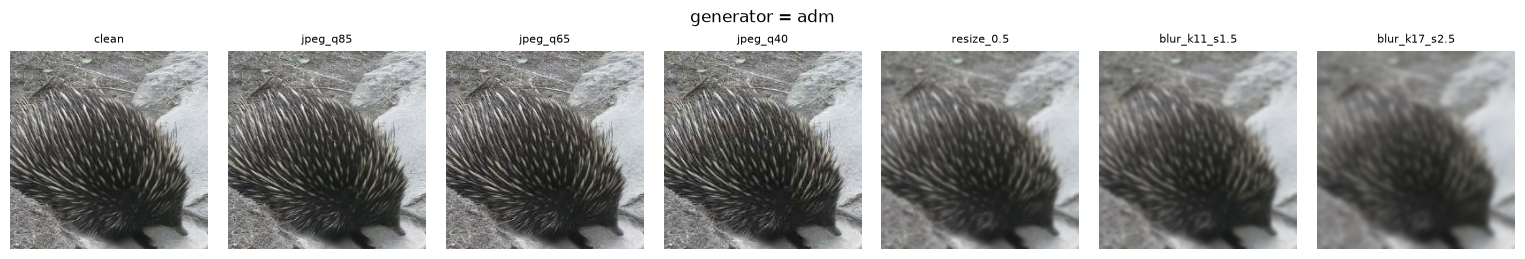

In [7]:
from src.models.base import load_image_array
test = [r for r in man.records if r.split == "test_benchmark"]
src = next(r for r in test if r.is_clean and r.label == 1)
variants = [r for r in test if r.parent_sha256 == src.sha256]
show = [src] + variants[:7]
fig, axes = plt.subplots(1, len(show), figsize=(2.2 * len(show), 2.6))
for ax, r in zip(np.atleast_1d(axes), show):
    ax.imshow(load_image_array(str(man.abs_path(r))))
    ax.set_title("clean" if r.is_clean else r.degradation.name, fontsize=8)
    ax.axis("off")
plt.suptitle(f"generator = {src.generator}")
plt.tight_layout(); plt.show()

### Đặc trưng chất lượng ảnh: Real và AI

Nếu chỉ 3 đặc trưng chất lượng (ước lượng JPEG Q, độ nét, năng lượng tần số cao) đã tách được Real và AI,
bộ dữ liệu có shortcut. Mọi mô hình phải vượt xa mức sàn này.

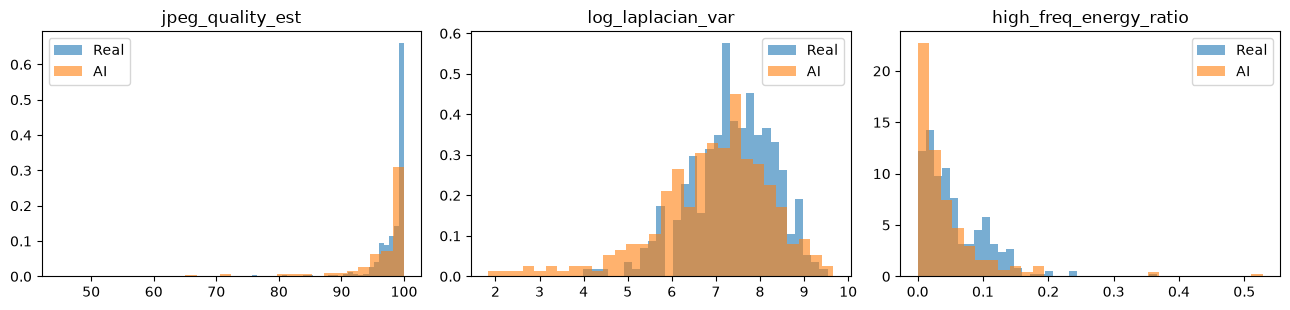

In [8]:
from src.core.contracts import QUALITY_FEATURE_NAMES
from src.data.quality import extract_quality_features
clean_seen = [r for r in man.records if r.is_clean and r.split in ("train_experts", "val_gating_fit", "test_benchmark")]
rng = np.random.default_rng(0)
sample = [clean_seen[i] for i in rng.choice(len(clean_seen), min(600, len(clean_seen)), replace=False)]
Q = np.stack([extract_quality_features(load_image_array(str(man.abs_path(r))), cfg).to_array() for r in sample])
yq = np.array([r.label for r in sample])
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for j, ax in enumerate(axes):
    for lab, name in ((0, "Real"), (1, "AI")):
        ax.hist(Q[yq == lab, j], bins=30, alpha=0.6, label=name, density=True)
    ax.set_title(QUALITY_FEATURE_NAMES[j]); ax.legend()
plt.tight_layout(); plt.show()

In [9]:
from src.data.shortcut_audit import audit_full
audit = audit_full(man, cfg)
print(f"pooled: AUROC={audit['auroc']:.3f}  accuracy={audit['accuracy']:.3f}  status={audit['status']}")
display(pd.DataFrame(audit["per_generator"]).T[["auroc", "accuracy", "n", "seen", "passed"]])

pooled: AUROC=0.636  accuracy=0.594  status=reported


,auroc,accuracy,n,seen,passed
adm,0.754,0.685,4000,True,False
sd_v1_4,0.631,0.595,4000,True,False
midjourney,0.693,0.651,4000,False,False
vqdm,0.727,0.672,4000,False,False
